# Lucknow air quality: cleaning the data (2020 to 2025)

This notebook takes your raw files and turns them into **one clean table**, one row per hour, with pollution and weather side by side.

**Before you start**, put these files in the **same folder as this notebook** (or upload them next to it):
1. The 8 pollution files from CPCB, named like `Raw_Data_2019_site_277_lalbagh_lucknow_cpcb_1Hr.csv` (2019 to 2026)
2. The ERA5 weather file, named like `reanalysis-era5-single-levels-timeseries-....csv` (unzip the ERA5 zip first)

Then run the cells **from top to bottom** (Shift + Enter on each). Every step prints something so you can see what happened.

## Step 1: Load the tools

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 2: Load the pollution files
Each file is one year. We find all 8, stick them together, and use the time column as the row label.

In [2]:
files = sorted(glob.glob("*Raw_Data_*lalbagh*1Hr.csv"))
print(len(files), "pollution files found (should be 8)")
for f in files:
    print("  ", f)

df = pd.concat([pd.read_csv(f, na_values=["NA"], parse_dates=["Timestamp"]) for f in files])
df = df.sort_values("Timestamp").set_index("Timestamp")
print("Rows:", len(df))
df.head()

8 pollution files found (should be 8)
   Raw_Data_2019_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2020_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2021_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2022_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2023_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2024_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2025_site_277_lalbagh_lucknow_cpcb_1Hr.csv
   Raw_Data_2026_site_277_lalbagh_lucknow_cpcb_1Hr.csv
Rows: 67920


,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),Benzene (µg/m³),...,MP-Xylene (µg/m³),AT (°C),RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s)
Timestamp,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00,448.57,NaN,9.92,81.40,50.70,NaN,34.13,0.05,14.61,0.0,...,NaN,NaN,82.54,0.17,243.19,NaN,NaN,2.0,1014.85,NaN
2019-01-01 01:00:00,418.42,NaN,9.83,67.79,43.47,NaN,31.85,0.25,15.34,0.0,...,NaN,NaN,84.49,0.09,196.08,NaN,NaN,2.0,1014.80,NaN
2019-01-01 02:00:00,367.90,NaN,8.58,57.36,36.39,NaN,28.47,0.21,24.94,0.0,...,NaN,NaN,84.51,0.11,136.20,NaN,NaN,2.0,1014.50,NaN
2019-01-01 03:00:00,317.60,NaN,7.51,43.98,28.43,NaN,24.56,1.92,30.97,0.0,...,NaN,NaN,81.57,0.26,225.26,NaN,NaN,2.0,1014.38,NaN
2019-01-01 04:00:00,261.03,NaN,5.25,36.03,21.93,NaN,16.55,0.43,37.70,0.0,...,NaN,NaN,83.04,0.12,240.64,NaN,NaN,2.0,1014.05,NaN


## Step 3: Keep only the columns we need
The raw files have 25 columns. Most are empty or unreliable (for example the weather sensors at the station change between years). We keep six pollutants and give them short names.

In [3]:
df = df.rename(columns={
    "PM2.5 (µg/m³)": "pm25",
    "PM10 (µg/m³)": "pm10",
    "NO2 (µg/m³)": "no2",
    "SO2 (µg/m³)": "so2",
    "CO (mg/m³)": "co",
    "Ozone (µg/m³)": "o3",
})
df = df[["pm25", "pm10", "no2", "so2", "co", "o3"]]
df = df.asfreq("h")          # make sure every hour has a row, even if it is empty
df.index.name = "time"

print("Percent of hours with no reading, per column:")
print((df.isna().mean() * 100).round(1))

Percent of hours with no reading, per column:
pm25     4.8
pm10    24.0
no2      2.9
so2      4.0
co       3.2
o3       1.8
dtype: float64


## Step 4: Clean the pollution data
Sensors sometimes give impossible readings. We turn these into blanks (`NaN`) rather than guessing a value. Each rule prints how many hours it changed.

| Rule | Why |
|---|---|
| PM2.5 or PM10 that is zero or negative | cannot be real |
| PM2.5 or PM10 of 995 or more | the instrument maxes out at about 1000; that is the machine's limit, not the air |
| CO of 9.99 or more | the CO column is capped at exactly 10 |
| Same PM value for 6 hours in a row | the sensor is stuck |

In [4]:
# Rule 1: zero or negative PM
for col in ["pm25", "pm10"]:
    bad = df[col] <= 0
    print(f"{col}: zero or negative -> {bad.sum()} hours removed")
    df.loc[bad, col] = np.nan

# Rule 2: instrument ceiling
for col in ["pm25", "pm10"]:
    bad = df[col] >= 995
    print(f"{col}: at the ceiling (>= 995) -> {bad.sum()} hours removed")
    df.loc[bad, col] = np.nan

bad = df["co"] >= 9.99
print(f"co: at the ceiling (>= 9.99) -> {bad.sum()} hours removed")
df.loc[bad, "co"] = np.nan

# Rule 3: stuck sensor (same value 6 or more hours in a row)
def stuck(series, n=6):
    run_id = (series != series.shift()).cumsum()                 # new number every time the value changes
    run_length = series.groupby(run_id).transform("size")        # how long each run is
    return (run_length >= n) & series.notna()

for col in ["pm25", "pm10"]:
    bad = stuck(df[col])
    print(f"{col}: stuck sensor -> {bad.sum()} hours removed")
    df.loc[bad, col] = np.nan

pm25: zero or negative -> 1 hours removed
pm10: zero or negative -> 0 hours removed
pm25: at the ceiling (>= 995) -> 15 hours removed
pm10: at the ceiling (>= 995) -> 14 hours removed
co: at the ceiling (>= 9.99) -> 19 hours removed
pm25: stuck sensor -> 14 hours removed
pm10: stuck sensor -> 87 hours removed


**What to expect:** PM2.5 loses only about 30 hours out of 67,920, so cleaning is very light. That is good: it means the raw data was mostly fine.

### Two warning flags (we mark these, we do NOT delete them)
Real events such as Diwali can look like errors, so we keep the values and just add a True/False column.

In [5]:
df["pm25_spike"] = df["pm25"].diff().abs() > 300       # jumped by more than 300 in one hour
df["pm25_above_pm10"] = df["pm25"] > df["pm10"]        # impossible: small particles cannot outweigh all particles

print("Spike hours flagged:", df["pm25_spike"].sum())
print("PM2.5 greater than PM10 hours flagged:", df["pm25_above_pm10"].sum())

Spike hours flagged: 21
PM2.5 greater than PM10 hours flagged: 46


## Step 5: Load the weather file (ERA5)
This file is hourly weather for the Lucknow area. It has no gaps. We load it and convert the units into ones that make sense.

In [6]:
era_files = glob.glob("*reanalysis-era5*.csv")
print("Weather files found:", era_files)

era = pd.concat([pd.read_csv(f, parse_dates=["valid_time"]) for f in era_files])
era = era.drop_duplicates("valid_time").set_index("valid_time").sort_index()

# unit conversions
era["temp_c"] = era["t2m"] - 273.15                     # kelvin -> celsius
dew_c = era["d2m"] - 273.15
era["humidity_pct"] = 100 * np.exp(17.625 * dew_c / (243.04 + dew_c)) / np.exp(17.625 * era["temp_c"] / (243.04 + era["temp_c"]))
era["wind_speed"] = np.hypot(era["u10"], era["v10"])    # wind speed from its two directions
era["blh_m"] = era["blh"]                               # boundary layer height in metres
era["pressure_hpa"] = era["sp"] / 100                   # pascals -> hPa
era["rain_mm"] = era["tp"] * 1000                       # metres -> millimetres

weather = era[["temp_c", "humidity_pct", "wind_speed", "blh_m", "pressure_hpa", "rain_mm"]]
print("Weather covers", weather.index.min(), "to", weather.index.max())
weather.head()

Weather files found: ['reanalysis-era5-single-levels-timeseries-sfc5a_faa7i.csv']
Weather covers 2020-01-01 00:00:00 to 2025-12-31 23:00:00


,temp_c,humidity_pct,wind_speed,blh_m,pressure_hpa,rain_mm
valid_time,,,,,,
2020-01-01 00:00:00,4.98970,97.441527,1.468152,25.932510,1005.6942,0.0
2020-01-01 01:00:00,4.96720,97.971614,1.755923,32.836510,1006.4858,0.0
2020-01-01 02:00:00,5.41158,98.078819,2.166113,39.906555,1007.1905,0.0
2020-01-01 03:00:00,7.39443,87.749821,2.052408,62.521873,1008.1159,0.0
2020-01-01 04:00:00,10.25924,86.431652,1.413305,124.166470,1008.9262,0.0


## Step 6: Fix the time zone (important!)
The weather file uses **UTC**, but the pollution data uses **Indian time (IST)**, which is 5 hours 30 minutes ahead. If we skip this, the weather would be matched to the wrong hours.

Adding 5h30m puts every weather reading at half past the hour, so we average the two neighbouring readings to get a value exactly on the hour.

In [7]:
weather = weather.copy()
weather.index = weather.index + pd.Timedelta(hours=5, minutes=30)

whole_hours = pd.date_range(weather.index.min().ceil("h"), weather.index.max().floor("h"), freq="h")
weather = weather.reindex(weather.index.union(whole_hours)).interpolate("time", limit=1).reindex(whole_hours)
weather.index.name = "time"

weather.head()

,temp_c,humidity_pct,wind_speed,blh_m,pressure_hpa,rain_mm
time,,,,,,
2020-01-01 06:00:00,4.978450,97.706571,1.612038,29.384510,1006.09000,0.0
2020-01-01 07:00:00,5.189390,98.025217,1.961018,36.371533,1006.83815,0.0
2020-01-01 08:00:00,6.403005,92.914320,2.109261,51.214214,1007.65320,0.0
2020-01-01 09:00:00,8.826835,87.090736,1.732857,93.344172,1008.52105,0.0
2020-01-01 10:00:00,12.476495,82.126432,1.549342,210.494935,1008.88715,0.0


## Step 7: Put pollution and weather in one table
We join them by time, add year / month / hour columns, and keep only **2020 to 2025** (the years where we have both).

In [8]:
data = df.join(weather, how="left")

data["year"] = data.index.year
data["month"] = data.index.month
data["hour"] = data.index.hour

data = data[(data["year"] >= 2020) & (data["year"] <= 2025)]
data = data.dropna(subset=["temp_c"])        # drop the first few hours of 2020 that have no weather yet

print("Final table:", data.shape[0], "rows,", data.shape[1], "columns")
data.head()

Final table: 52602 rows, 17 columns


,pm25,pm10,no2,so2,co,o3,pm25_spike,pm25_above_pm10,temp_c,humidity_pct,wind_speed,blh_m,pressure_hpa,rain_mm,year,month,hour
time,,,,,,,,,,,,,,,,,
2020-01-01 06:00:00,435.26,NaN,38.22,8.04,0.0,39.57,False,False,4.978450,97.706571,1.612038,29.384510,1006.09000,0.0,2020,1,6
2020-01-01 07:00:00,367.16,NaN,36.22,5.51,0.0,31.75,False,False,5.189390,98.025217,1.961018,36.371533,1006.83815,0.0,2020,1,7
2020-01-01 08:00:00,314.28,NaN,65.57,1.25,0.0,34.52,False,False,6.403005,92.914320,2.109261,51.214214,1007.65320,0.0,2020,1,8
2020-01-01 09:00:00,271.46,NaN,103.78,NaN,0.0,38.61,False,False,8.826835,87.090736,1.732857,93.344172,1008.52105,0.0,2020,1,9
2020-01-01 10:00:00,209.19,NaN,58.60,2.04,NaN,35.67,False,False,12.476495,82.126432,1.549342,210.494935,1008.88715,0.0,2020,1,10


**What to expect:** about 52,600 rows.

## Step 8: Check that it looks right
Always look at the result before using it. First, how complete is each year?

In [9]:
print("Percent of hours with a valid PM2.5 reading, by year:")
print((data["pm25"].notna().groupby(data["year"]).mean() * 100).round(1))

Percent of hours with a valid PM2.5 reading, by year:
year
2020    96.3
2021    96.7
2022    96.3
2023    97.0
2024    95.2
2025    90.8
Name: pm25, dtype: float64


Second, a picture. Pollution should be **high in winter (Nov to Feb) and low in the monsoon (Jul to Sep)**, every year. If the picture shows that, the cleaning and the dates are working.

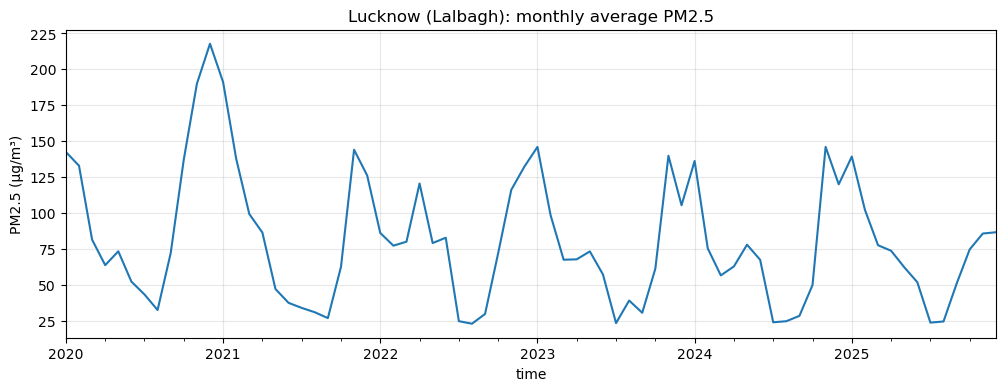

In [10]:
monthly = data["pm25"].resample("MS").mean()

plt.figure(figsize=(12, 4))
monthly.plot()
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Lucknow (Lalbagh): monthly average PM2.5")
plt.grid(alpha=0.3)
plt.show()

And a first look at the idea behind the whole project: **when the boundary layer is low (air is trapped near the ground), is pollution higher?**

In [11]:
winter = data[data["month"].isin([11, 12, 1])].dropna(subset=["pm25", "blh_m"])
groups = pd.qcut(winter["blh_m"], 4, labels=["lowest", "low-mid", "high-mid", "highest"])
print("Average winter PM2.5 by boundary layer height (lowest = most trapped air):")
print(winter.groupby(groups, observed=True)["pm25"].mean().round(0))

Average winter PM2.5 by boundary layer height (lowest = most trapped air):
blh_m
lowest      181.0
low-mid     142.0
high-mid    115.0
highest     107.0
Name: pm25, dtype: float64


## Step 9: Save the clean table
This writes a CSV file next to the notebook. From here you can build your model, dashboard, or Power BI report from this one file.

In [12]:
data.to_csv("lucknow_clean_2020_2025.csv")
print("Saved: lucknow_clean_2020_2025.csv")

Saved: lucknow_clean_2020_2025.csv
